In [12]:
import numpy as np
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
import torch
import sys 
import tifffile 
from pathlib import Path
from scripts.utils import reshape_disp, reshape_img, rmse
from scripts.dataset import TractionDataset

sys.path.append('/Users/josephinelahmani/Desktop/vxmorph') 
import importlib
import network
import network.models
import scripts.dataset
importlib.reload(network.models)
importlib.reload(network)
importlib.reload(scripts.dataset)
from scripts.dataset import TractionDataset

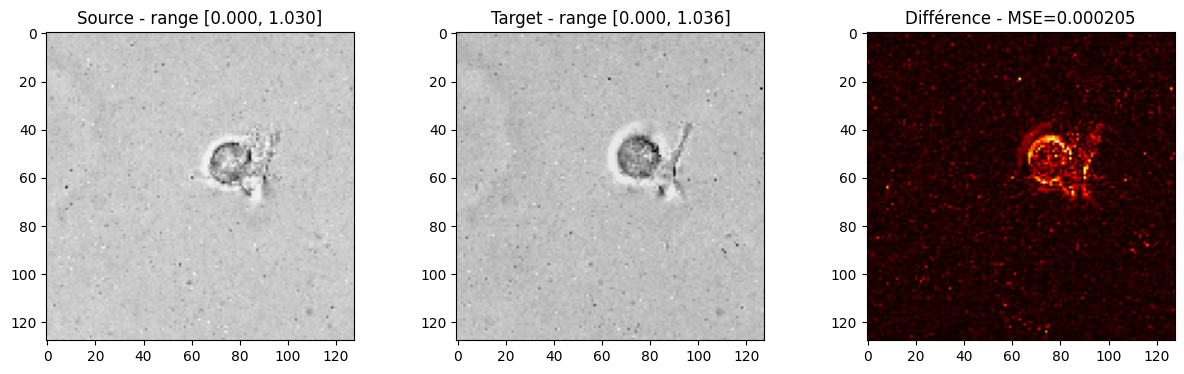

In [33]:
train_dataset = TractionDataset(Path('/Users/josephinelahmani/Desktop/data_deep/micro/train'))

sample = train_dataset[0]
source, target = sample["source"], sample["target"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

mid_z = source.shape[1] // 2 

axes[0].imshow(source[0, mid_z], cmap='gray')
axes[0].set_title(f"Source - range [{source.min():.3f}, {source.max():.3f}]")

axes[1].imshow(target[0, mid_z], cmap='gray')
axes[1].set_title(f"Target - range [{target.min():.3f}, {target.max():.3f}]")

axes[2].imshow((source - target).abs()[0, mid_z], cmap='hot')
axes[2].set_title(f"Différence - MSE={((source-target)**2).mean():.6f}")

plt.show()

In [60]:
def plot_loss(folder:str, loss_part:str, init_epoch:int=0):
    if loss_part == 'total':
        name = 'loss'
    else:
        name = f'loss_{loss_part}'
    
    folder_name = folder.split('/')[-1]

    lr_match = re.search(r'lr(\d+)em(\d+)', folder_name)
    lr = float(f"{lr_match.group(1)}e-{lr_match.group(2)}") if lr_match else None

    ab_match = re.search(r'alpha_beta_([\d.]+)_([\d.]+)', folder_name)
    alpha = float(ab_match.group(1)) if ab_match else None

    train_logs = pd.read_csv(f'{folder}/logs_train.csv').iloc[init_epoch:]
    val_logs  = pd.read_csv(f'{folder}/logs_validation.csv').iloc[init_epoch:]

    epochs = range(init_epoch + 1, len(train_logs) + init_epoch + 1)
    
    plt.plot(epochs, train_logs[name], label='train loss', color='blue')
    plt.plot(epochs, val_logs[name], label='val loss', color='red')
    plt.title(f'{name}, Lr={lr}, alpha=beta={alpha}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    
def load_model(folder: str, model_type: str):
        os.environ['NEURITE_BACKEND'] = 'pytorch'
        os.environ['VXM_BACKEND'] = 'pytorch'

        device = 'cuda' if torch.cuda.is_available() else 'cpu'

        model_path= f'{folder}/best.pt' 

        if model_type == 'aniso':
                model = network.models.NetworkPairwiseAnisotropic(
                        ndim=3,
                        source_channels=1,
                        target_channels=1,
                        features=[16, 32, 32, 64, 64],
                ).to(device)

        else :
                model = network.models.NetworkPairwise(
                        ndim=3,
                        source_channels=1,
                        target_channels=1,
                        features=[16, 32, 32, 64],
                ).to(device)
                
        checkpoint = torch.load(model_path, map_location=device)

        model.load_state_dict(checkpoint)
        model.eval()
        
        return model

import torchio as tio

def get_img_and_results(img_path: Path, model):
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
        
        img_raw = tifffile.imread(img_path)
        q1, q99 = np.quantile(img_raw, [0.01, 0.99])
        img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)
        img_padded = np.stack([reshape_img(img[1, 1], 32), reshape_img(img[0, 1], 32)], axis=0)

        source_vxm = torch.from_numpy(img_padded[0]).unsqueeze(0).float().to(device)
        target_vxm = torch.from_numpy(img_padded[1]).unsqueeze(0).float().to(device)
        
        
        subject = tio.Subject(
                source=tio.ScalarImage(tensor=source_vxm),
                target=tio.ScalarImage(tensor=target_vxm),
        )
        
        source_vxm = subject.source.data.unsqueeze(0)
        target_vxm = subject.target.data.unsqueeze(0)
        
        with torch.no_grad():  
                displacement, warped_source = model(source_vxm, target_vxm, 
                                                return_warped_source=True)

        return img_padded, displacement, warped_source


def check_vxm(img_padded: np.ndarray, warped_image:np.ndarray, z_stack: int):
        fig, axes = plt.subplots(1, 5, figsize=(24, 6))

        vmin_im, vmax_im = np.min(img_padded[0, z_stack]), np.max(img_padded[0, z_stack])
        im0 = axes[0].imshow(img_padded[0, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[0].set_title('I1')
        fig.colorbar(im0, ax=axes[0])
        im1 = axes[1].imshow(img_padded[1, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[1].set_title('I2')
        fig.colorbar(im1, ax=axes[1])
        im2 = axes[2].imshow(warped_image[z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[2].set_title("I2(x+u) (warped source)")
        fig.colorbar(im2, ax=axes[2])
        
        diff_im = np.abs(img_padded[1, z_stack] - img_padded[0, z_stack])
        diff_w_im = np.abs(warped_image[z_stack] - img_padded[0, z_stack])
        vmin = np.min([np.min(diff_im), np.min(diff_w_im)])
        vmax = np.max([np.max(diff_im), np.max(diff_w_im)])
        
        im3 = axes[3].imshow(np.abs(warped_image[z_stack] - img_padded[0, z_stack]), vmin=vmin, vmax=vmax)
        axes[3].set_title("I2(x+u)-I1")
        fig.colorbar(im3, ax=axes[3])
        im4 = axes[4].imshow(np.abs(img_padded[1, z_stack] - img_padded[0, z_stack]), vmin=vmin, vmax=vmax)
        axes[4].set_title("I2-I1")
        fig.colorbar(im4, ax=axes[4])
        plt.show()

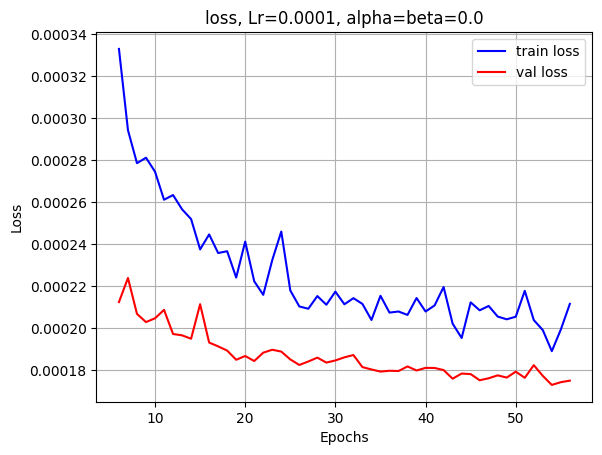

In [71]:
results_folder = '/Users/josephinelahmani/helix_mount/nn_dis/results/aniso_lr1em4_alpha_beta_0_400_mask_no_init'
path_img = Path('/Users/josephinelahmani/helix_mount/data/micro/val/250218_WT_1p5CD100RGD_pos10_t0021_t0023.tiff')
    
plot_loss(results_folder, 'total', 5)
model_aniso = load_model(results_folder, 'aniso')

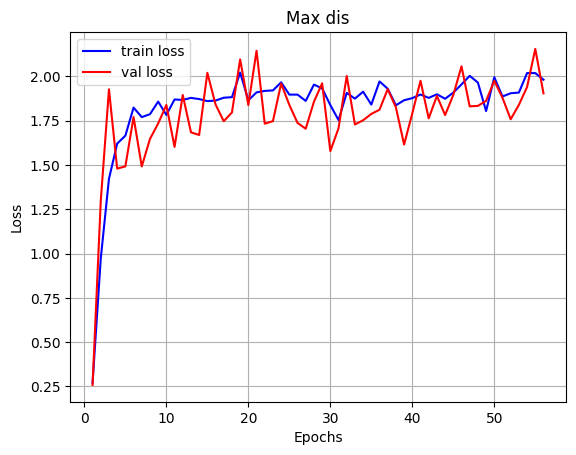

In [72]:
train_logs = pd.read_csv(f'{results_folder}/logs_train.csv')
val_logs  = pd.read_csv(f'{results_folder}/logs_validation.csv')
    
epochs = range(1, len(train_logs) + 1)

plt.plot(epochs, train_logs["max_dis"], label='train loss', color='blue')
plt.plot(epochs, val_logs["max_dis"], label='val loss', color='red')
plt.title(f'Max dis')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

(2, 32, 128, 128)
Min: -0.5890
Max: 0.7373
Mean abs: 0.2073


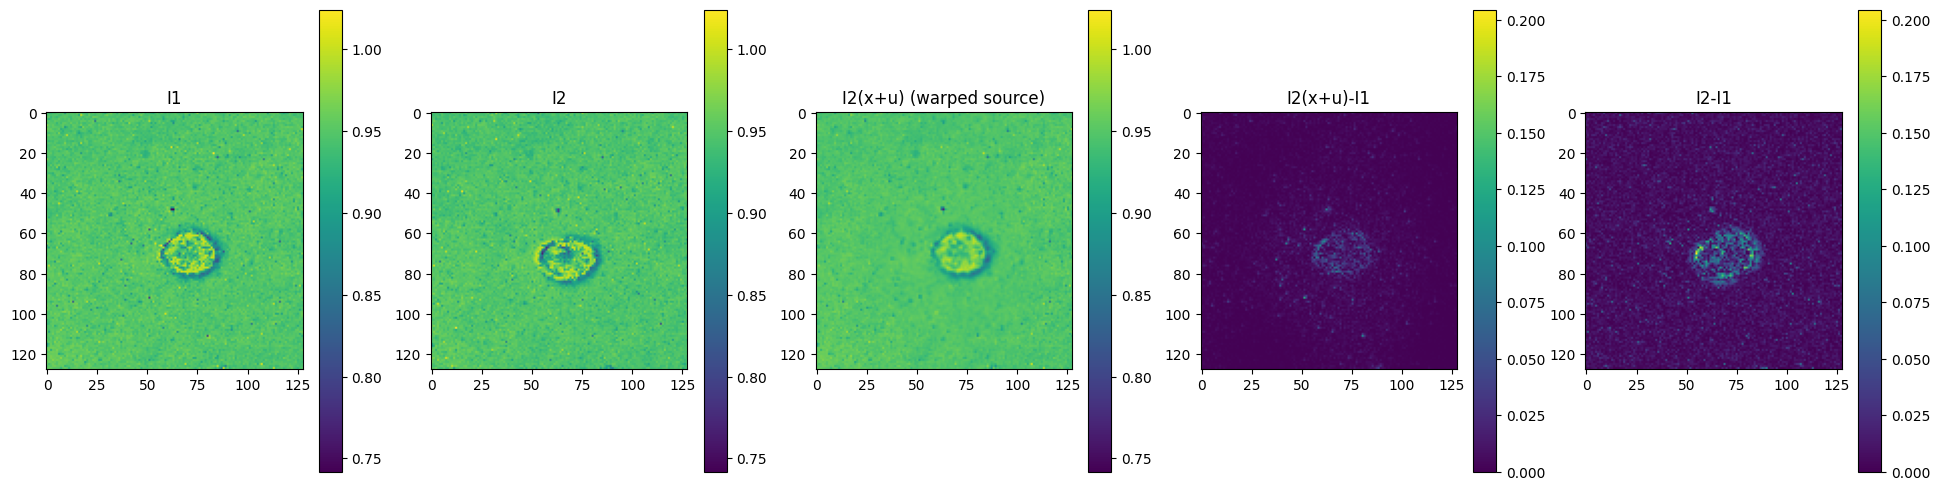

In [73]:
img_padded, displacement, warped_source = get_img_and_results(path_img, model_aniso)
print(img_padded.shape)

im_vxm = warped_source.detach().numpy()[0,0]

dis = displacement.detach().numpy()

print(f"Min: {displacement.min():.4f}")
print(f"Max: {displacement.max():.4f}")
print(f"Mean abs: {displacement.abs().mean():.4f}")

z = 16

check_vxm(img_padded, im_vxm, z_stack = z)

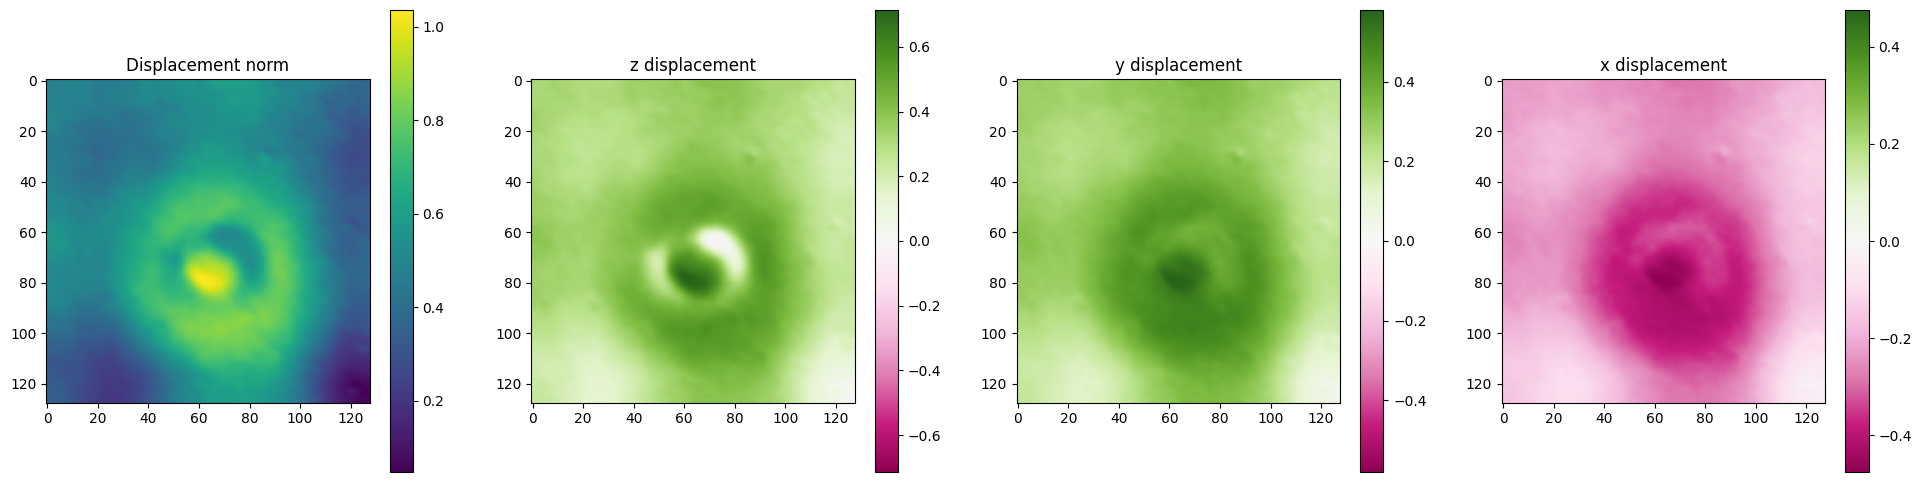

In [74]:
z_stack = 9
dis_z_max = np.max(np.abs(dis[0, 0, z_stack]))
dis_y_max = np.max(np.abs(dis[0, 1, z_stack]))
dis_x_max = np.max(np.abs(dis[0, 2, z_stack]))


fig, axes = plt.subplots(1, 4, figsize=(24, 6))

im0 = axes[0].imshow(np.linalg.norm(dis[0, :, z_stack], axis=0))
fig.colorbar(im0, ax = axes[0])
axes[0].set_title('Displacement norm')
im1 = axes[1].imshow(dis[0, 0, z_stack], cmap = 'PiYG', vmin = -dis_z_max, vmax = dis_z_max)
fig.colorbar(im1, ax = axes[1])
axes[1].set_title('z displacement')
im2 = axes[2].imshow(dis[0, 1, z_stack], cmap = 'PiYG', vmin = -dis_y_max, vmax = dis_y_max)
fig.colorbar(im2, ax = axes[2])
axes[2].set_title('y displacement')
im3 = axes[3].imshow(dis[0, 2, z_stack], cmap = 'PiYG', vmin = -dis_x_max, vmax = dis_x_max)
fig.colorbar(im3, ax = axes[3])
axes[3].set_title('x displacement')
plt.show()

In [6]:
import optical_flow.algorithms
importlib.reload(optical_flow.algorithms)
from optical_flow.algorithms import tv_l1, fista_of, hs_of
import yaml

base_path = Path('/Users/josephinelahmani/Desktop/data_generation/data/elas/3d/tractions_zones_E_1000.0_nu_0.4_nb_zones_7_seed_10')

flow_dir = base_path / "computed_flows"
flow_dir.mkdir(exist_ok=True)

spacing = [1.0, 0.13, 0.13]

with open("/Users/josephinelahmani/Desktop/nn_dis/configs/optical_flow.yaml", "r") as f:
    cfg = yaml.safe_load(f)
    
def compute_ofs_and_dis(path_img, path_dis, spacing):
    img_raw = np.load(path_img)
    dis_gt = np.load(path_dis)
    
    dis_gt_padded = reshape_disp(dis_gt, 32)
    
    q1, q99 = np.quantile(img_raw, [0.01, 0.99])
    img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

    img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)

    mask_padded = img_padded[0] > 0.1
    
    fista_params = SimpleNamespace(**cfg["optical_flow"]["fista"])
    hs_params = SimpleNamespace(**cfg["optical_flow"]["hs"])
    tvl1_params = SimpleNamespace(**cfg["optical_flow"]["tvl1"])

    dis_fista = fista_of(img_padded, fista_params, True)
    dis_hs = hs_of(img_padded, hs_params, True)
    dis_tvl1 = tv_l1(img_padded, tvl1_params, True)
    
    dis_fista_ = dis_fista[:,1:,:,:,:]
    dis_fista_final = np.stack([dis_fista_[i] * mask_padded for i in range(dis_fista_.shape[0])])

    dis_hs_ = dis_hs[:,1:,:,:,:]
    dis_hs_final = np.stack([dis_hs_[i] * mask_padded * spacing[i] for i in range(dis_hs_.shape[0])])

    dis_tvl1_ = dis_tvl1[:,1:,:,:,:]
    dis_tvl1_final = np.stack([dis_tvl1_[i] * mask_padded * spacing[i] for i in range(dis_tvl1_.shape[0])])

    results = {
            "gt": dis_gt_padded,
            "fista": dis_fista_final,
            "hs": dis_hs_final,
            "tvl1": dis_tvl1_final,
            "mask": mask_padded
        }
    
    return results

for path_img in sorted(base_path.glob("im_*_img.npy")):
    name = path_img.name
    index = name.split("_")[1]
    path_dis = path_img.with_name(path_img.name.replace("_img.npy", "_ugt.npy"))
    
    result = compute_ofs_and_dis(path_img, path_dis, spacing)
    
    np.save(flow_dir / f"flow_gt_im_{index}.npy",     result["gt"])
    np.save(flow_dir / f"flow_fista_im_{index}.npy",  result["fista"])
    np.save(flow_dir / f"flow_hs_im_{index}.npy",     result["hs"])
    np.save(flow_dir / f"flow_tvl1_im_{index}.npy",   result["tvl1"])

img size (21, 17, 17)


KeyboardInterrupt: 

In [18]:
def vmx_rmse(path_img, model):
    img_raw = np.load(path_img)
    
    q1, q99 = np.quantile(img_raw, [0.01, 0.99])
    img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

    img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)

    mask_padded = img_padded[0] > 0.1
    
    source_vxm = torch.from_numpy(reshape_img(img[1], 32)).unsqueeze(0).unsqueeze(0).to(device)
    target_vxm = torch.from_numpy(reshape_img(img[0], 32)).unsqueeze(0).unsqueeze(0).to(device)
    
    displacement, warped_source = model(
        source_vxm, target_vxm,
        return_warped_source=True,
    )

    dis_vxm = displacement.detach().numpy()
    
    dis_vxm_final = np.stack([dis_vxm[:,i] * mask_padded for i in range(dis_vxm.shape[1])])
    
    ##### CONVENTION ??
    results = {
        "flow": dis_vxm_final
    }
    
    return results, warped_source

In [19]:
base_path = Path('/Users/josephinelahmani/Desktop/data_generation/data/elas/3d/tractions_zones_E_1000.0_nu_0.4_nb_zones_7_seed_10')

flow_dir = base_path / "computed_flows"
flow_dir.mkdir(exist_ok=True)

for path_img in sorted(base_path.glob("im_*_img.npy")):
    name = path_img.name
    index = name.split("_")[1]
    path_dis = path_img.with_name(path_img.name.replace("_img.npy", "_ugt.npy"))
    
    result_vxm, _ = vmx_rmse(path_img, model)
    
    np.save(flow_dir / f"flow_vxm{index}.npy", result_vxm["flow"])

In [21]:
def compute_rmse(index, rmse_summary, flow_dir):
    dis_gt = np.load(flow_dir / f"flow_gt_im_{index}.npy")
    dis_fista = np.load(flow_dir / f"flow_fista_im_{index}.npy")
    dis_hs = np.load(flow_dir / f"flow_hs_im_{index}.npy")
    dis_tvl1 = np.load(flow_dir / f"flow_tvl1_im_{index}.npy")
    dis_vxm = np.load(flow_dir / f"flow_vxm_im_{index}.npy")
    
    rmse_fista = rmse(dis_fista, dis_gt)
    rmse_hs = rmse(dis_hs, dis_gt)
    rmse_tvl1 = rmse(dis_tvl1, dis_gt)
    rmse_vxm = rmse(dis_vxm, dis_gt)

    rmse_summary.append({
        "index": index,
        "rmse_fista": float(rmse_fista),
        "rmse_hs": float(rmse_hs),
        "rmse_tvl1": float(rmse_tvl1),
        "rmse_vxm": float(rmse_vxm),
    })
    
    return rmse_summary


rmse_summary = []

for path_img in sorted(base_path.glob("im_*_img.npy")):
    name = path_img.name
    index = name.split("_")[1]
    
    rmse_summary = compute_rmse(index, rmse_summary, flow_dir)

In [30]:
methods = ['rmse_fista', 'rmse_hs', 'rmse_tvl1', 'rmse_vxm']

avg = {m: np.mean([d[m] for d in rmse_summary]) for m in methods}

for method, value in avg.items():
    print(f"{method} : {value}")

rmse_fista : 0.03315940606223052
rmse_hs : 0.0422688275570142
rmse_tvl1 : 0.042732238872059895
rmse_vxm : 0.05433924123644829


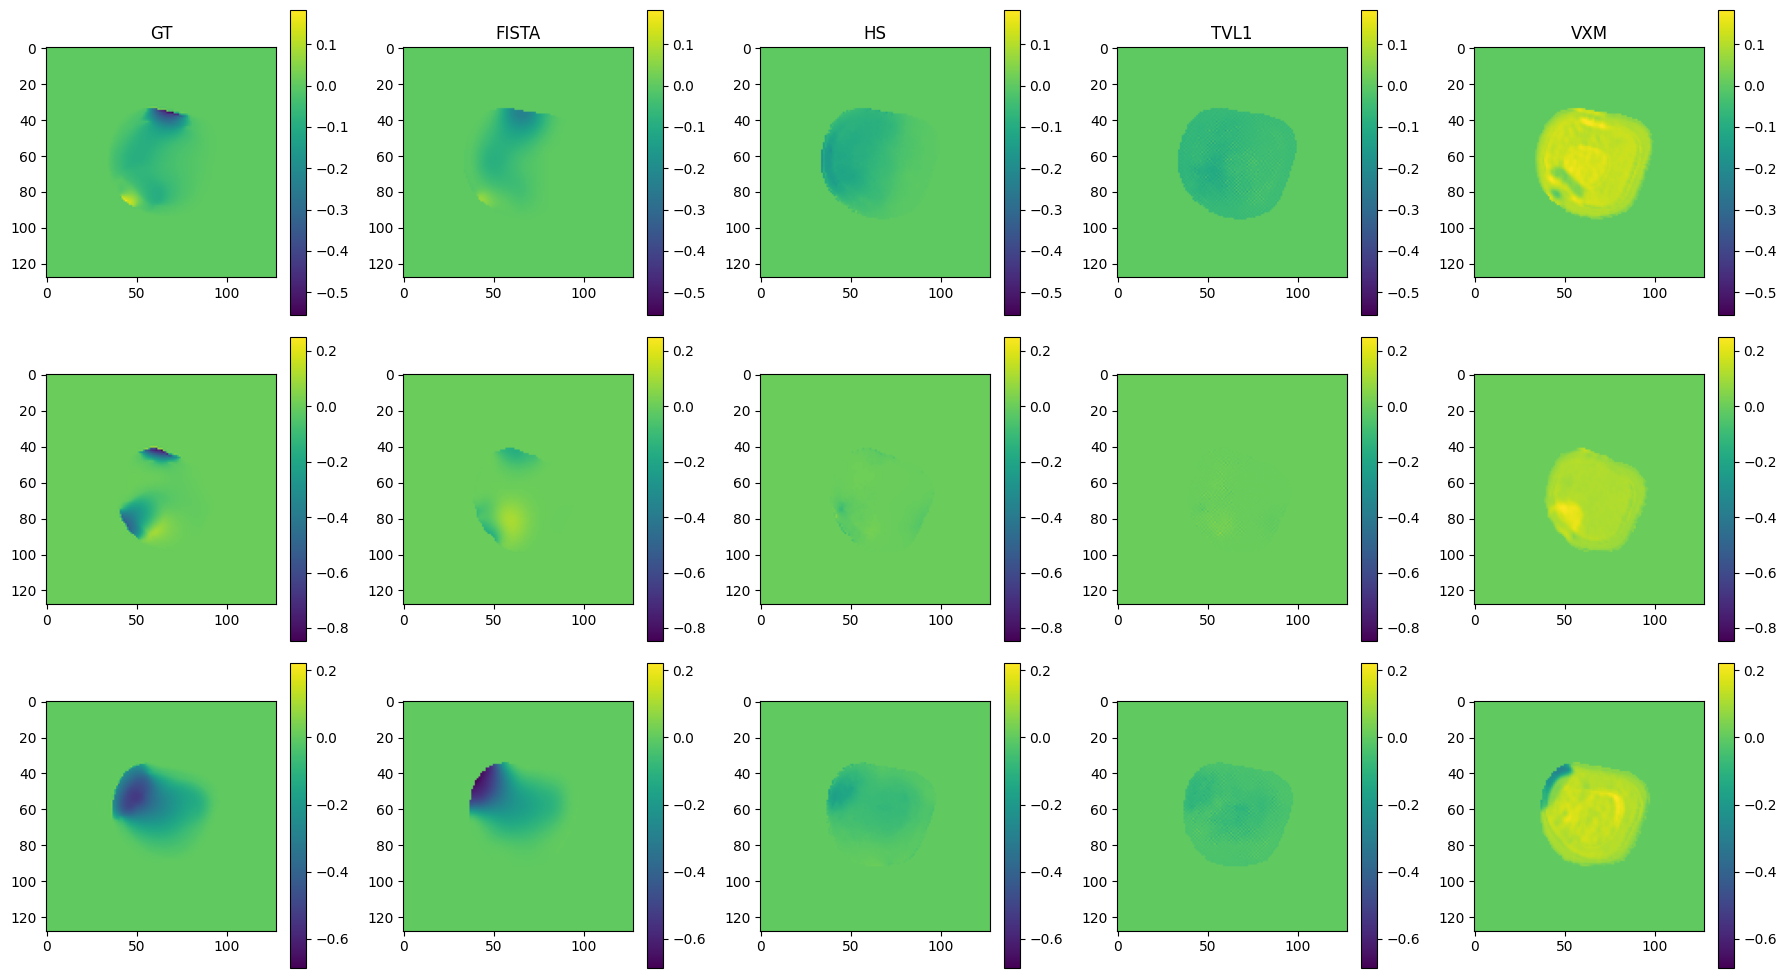

In [31]:
indices = ["00", "01", "02"]
methods = ["gt", "fista", "hs", "tvl1", "vxm_alpha_beta_0_001_80_epoch"]
method_titles = ["GT", "FISTA", "HS", "TVL1", "VXM"]

frame = 12
ax = 2

fig, axes = plt.subplots(len(indices), len(methods), figsize=(18, 10))

for i, index in enumerate(indices):
    dis = {
        m: np.load(flow_dir / f"flow_{m}_im_{index}.npy")
        for m in methods
    }
    all_values = np.concatenate([dis[m][ax, 0, frame, :].ravel() for m in methods])
    vmin, vmax = all_values.min(), all_values.max()
    
    for j, m in enumerate(methods):
        im = axes[i, j].imshow(dis[m][ax, 0, frame, :], vmin=vmin, vmax=vmax)
        fig.colorbar(im, ax=axes[i, j])
        
        if i == 0:
            axes[i, j].set_title(method_titles[j], fontsize=12)

plt.tight_layout()
plt.show()

In [20]:
import scipy.ndimage as ndi

from quantities_computation import strain_mask, deformation, stress_mask, compute_normals_from_mask_3d, compute_traction_3d

path_img = Path('/Users/josephinelahmani/Desktop/data_generation/data/elas/3d/tractions_zones_E_1000.0_nu_0.4_nb_zones_7_seed_10/im_00_img.npy')

img_raw = np.load(path_img)
q1, q99 = np.quantile(img_raw, [0.01, 0.99])
img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)

mask = img_padded[0] > 0.1

mask_eroded = ndi.binary_erosion(mask)
inner_boundary_gt = mask_eroded & (~ndi.binary_erosion(mask_eroded))
normals = compute_normals_from_mask_3d(mask_eroded)
normals[:, ~inner_boundary_gt] = 0
        
def compute_lame(E, nu):
    """
    Computes the Lamé parameters (μ and λ) from Young’s modulus and Poisson’s ratio.

    Args:
        E (float):
            Young’s modulus of the material.
        nu (float):
            Poisson’s ratio of the material.

    Returns:
        tuple[float, float]:
            - `mu_e` (float): Shear modulus (μ).
            - `lambda_e` (float): First Lamé parameter (λ).
    """
    lambda_e = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    mu_e = E / (2.0 * (1.0 + nu))
    return mu_e, lambda_e

E = 1000.0
nu = 0.4

mu, lambda_ = compute_lame(E, nu)

def compute_mec_stuff(index, flow_dir):

    displacements = {
        "gt":    np.load(flow_dir / f"flow_gt_im_{index}.npy"),
        "fista": np.load(flow_dir / f"flow_fista_im_{index}.npy"),
        "hs":    np.load(flow_dir / f"flow_hs_im_{index}.npy"),
        "tvl1":  np.load(flow_dir / f"flow_tvl1_im_{index}.npy"),
    }
    
    results = {}
    dis_gt = displacements["gt"]
    strain_gt = strain_mask(dis_gt, [1, 1, 1], mask)
    def_grad_gt = deformation(strain_gt)
    stress_gt = stress_mask(strain_gt, mu, lambda_)
    traction_gt = compute_traction_3d(stress_gt[:,:,0], -normals)

    results["gt"] = {
        "displacement": dis_gt,        
        "deformation":  def_grad_gt,
        "strain":       strain_gt,
        "stress":       stress_gt,
        "normals":      normals,
        "traction":     traction_gt,
    }

    methods = ["fista", "hs", "tvl1"]
    
    for method in methods:
        dis = displacements[method]
        
        strain = strain_mask(dis, [1, 1, 1], mask)
        def_grad = deformation(strain)
        stress = stress_mask(strain, mu, lambda_)
        traction = compute_traction_3d(stress[:,:,0], -normals)

        results[method] = {
            "displacement": dis,        
            "deformation":  def_grad,
            "strain":       strain,
            "stress":       stress,
            "normals":      normals,
            "traction":     traction,
            
            "rmse_displacement": rmse(dis, dis_gt),
            "rmse_deformation":  rmse(def_grad, def_grad_gt),
            "rmse_strain":       rmse(strain, strain_gt),
            "rmse_stress":       rmse(stress, stress_gt),
            "rmse_traction":     rmse(traction, traction_gt),
        }

    return results

In [21]:
base_path = Path('/Users/josephinelahmani/Desktop/data_generation/data/elas/3d/tractions_zones_E_1000.0_nu_0.4_nb_zones_7_seed_10')

flow_dir = base_path / "computed_flows"
flow_dir.mkdir(exist_ok=True)

results = compute_mec_stuff("00", flow_dir)

In [22]:
metrics = ["displacement", "deformation", "strain", "stress", "traction"]
methods = ["fista", "hs", "tvl1"]

for metric in metrics:
    print(f"\n{metric}")
    for method in methods:
        val = results[method][f"rmse_{metric}"]
        print(f"{method:<8} : {val:.6e}")


displacement
fista    : 1.775058e-02
hs       : 3.716127e-02
tvl1     : 3.893741e-02

deformation
fista    : 8.096015e-03
hs       : 1.485174e-02
tvl1     : 1.980343e-02

strain
fista    : 3.441167e-03
hs       : 7.831259e-03
tvl1     : 1.022172e-02

stress
fista    : 8.635724e+00
hs       : 1.969392e+01
tvl1     : 2.170590e+01

traction
fista    : 7.268423e+00
hs       : 2.020727e+01
tvl1     : 1.500010e+01


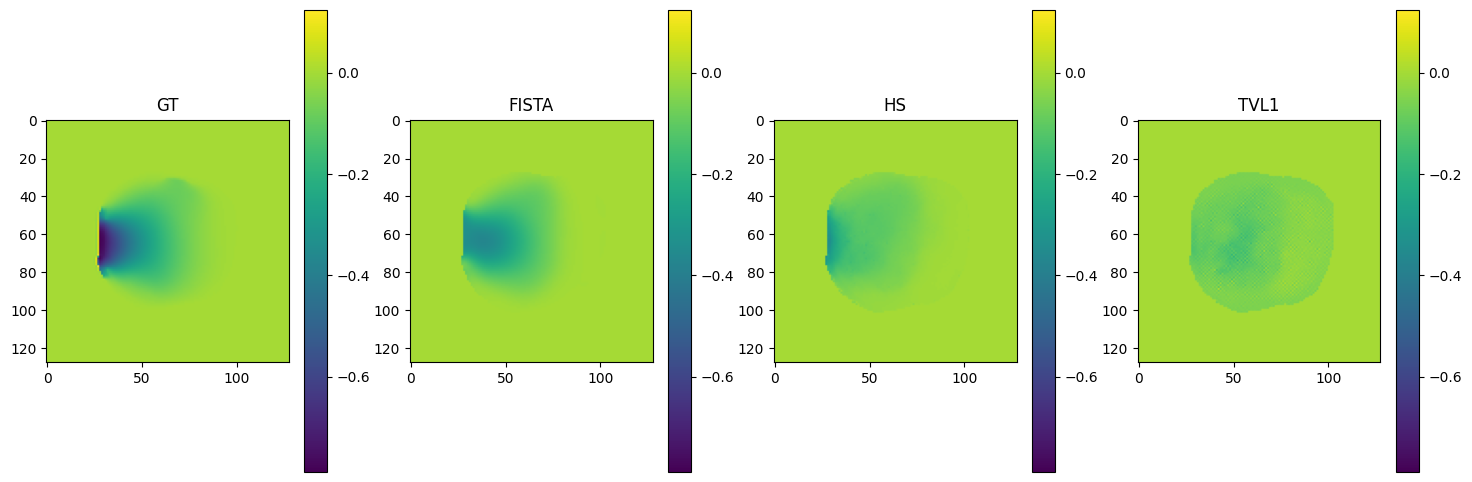

In [96]:
methods = ["gt", "fista", "hs", "tvl1"]
method_titles = ["GT", "FISTA", "HS", "TVL1"]
frame = 14
ax = 2

fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['displacement'][ax, 0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['displacement'][ax, 0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

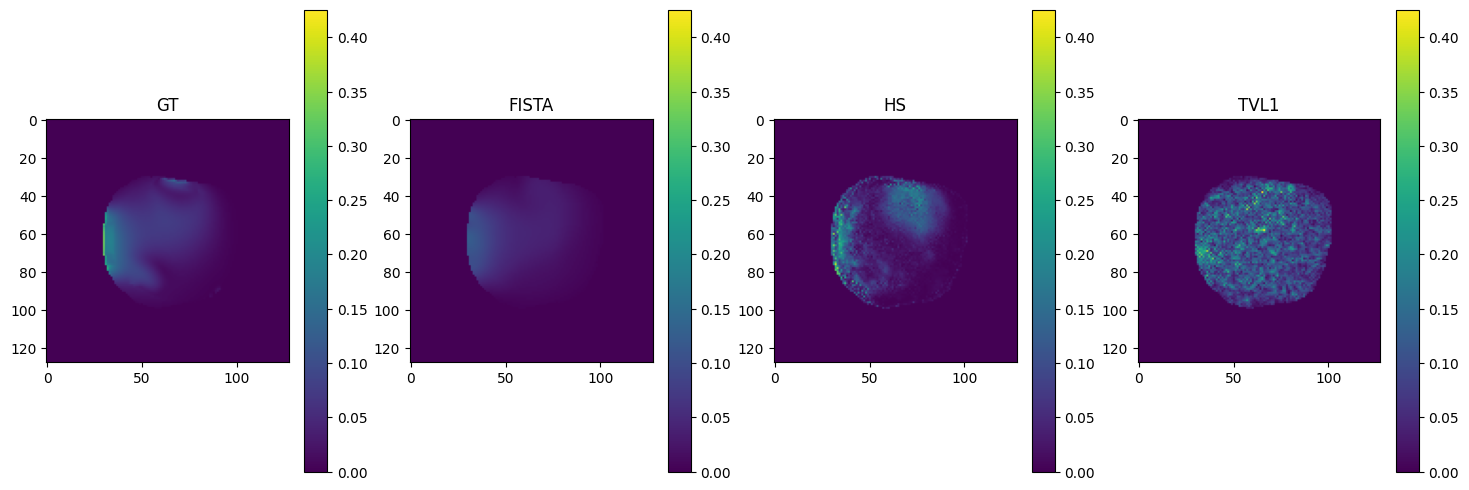

In [97]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['deformation'][0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['deformation'][0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

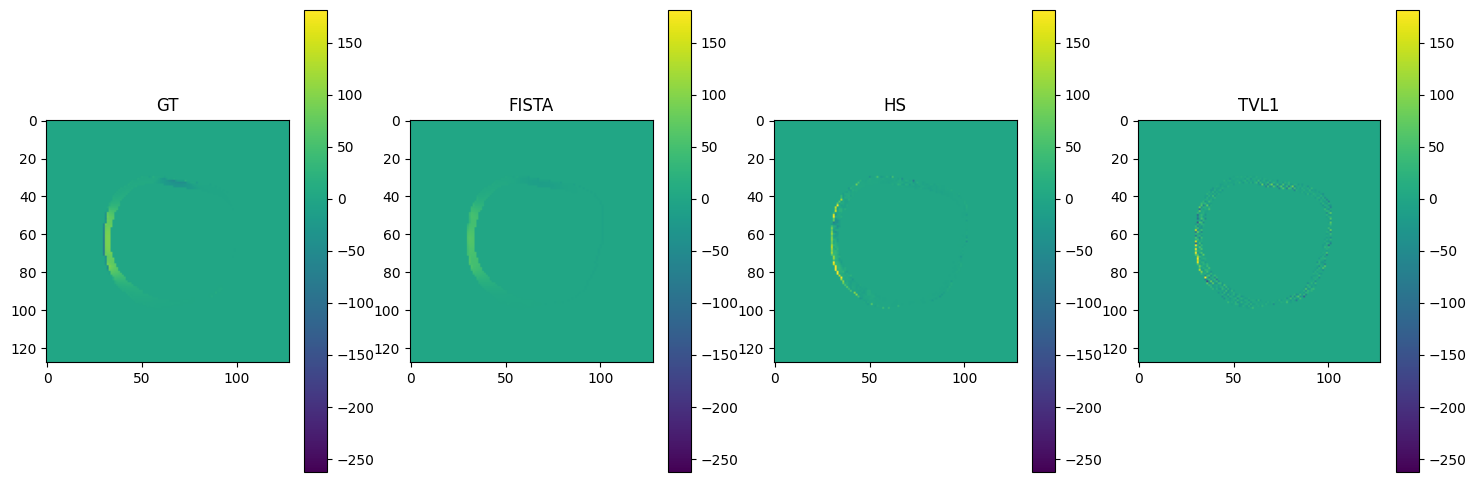

In [100]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['traction'][1, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['traction'][2, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)